<a href="https://colab.research.google.com/github/Angelinat3/IP-CV_odd-Angelina-Thennessa-Jo-3/blob/main/Pertemuan8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


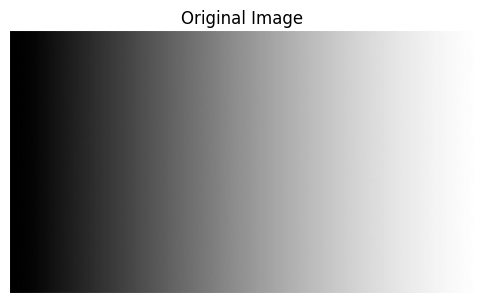

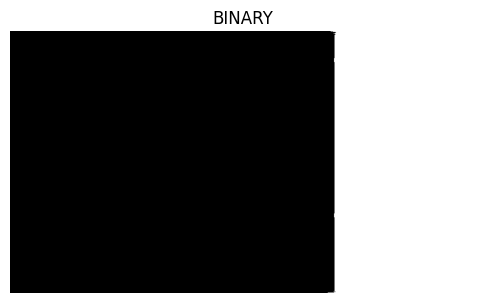

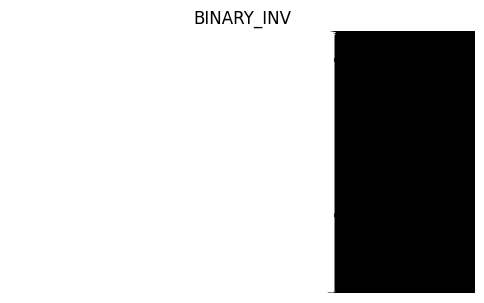

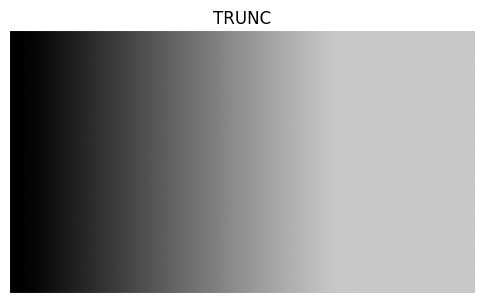

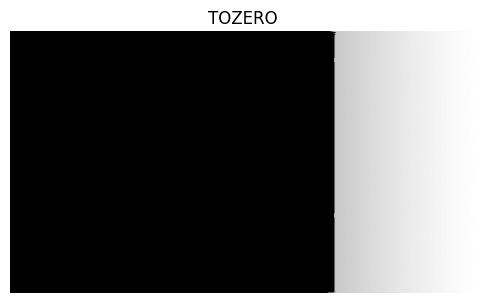

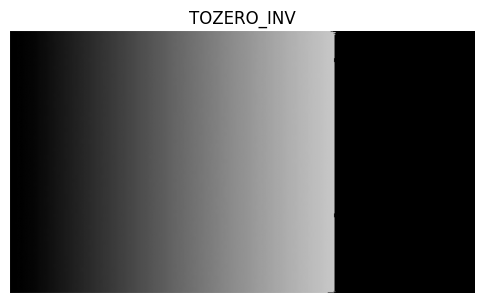

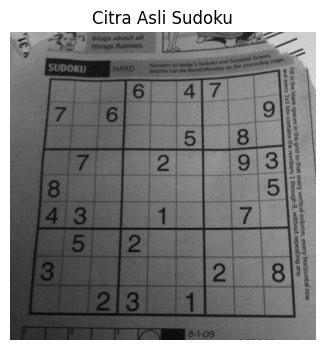

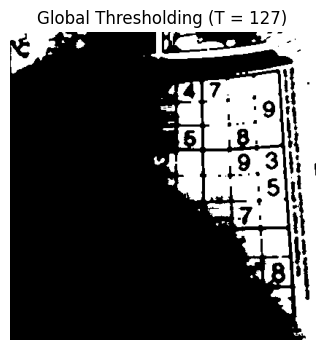

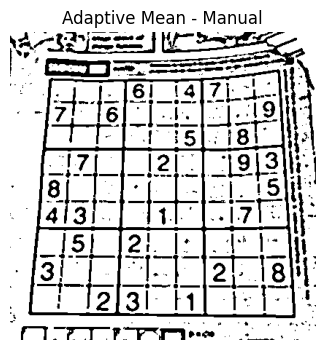

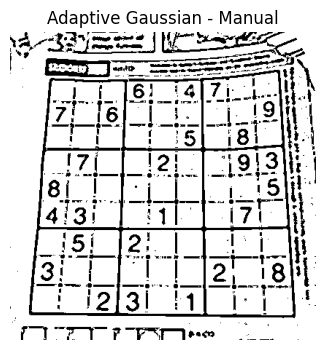

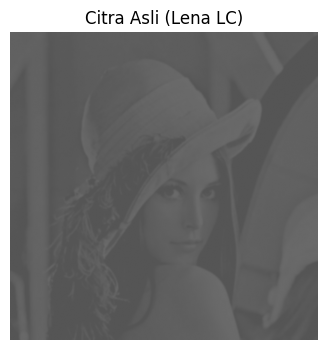

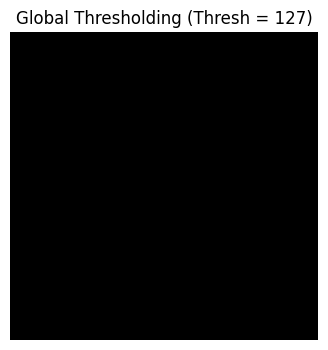

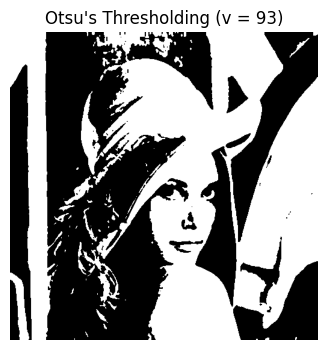

Memakai file KTP: /content/drive/MyDrive/PCVK/Images/ktp.jpg


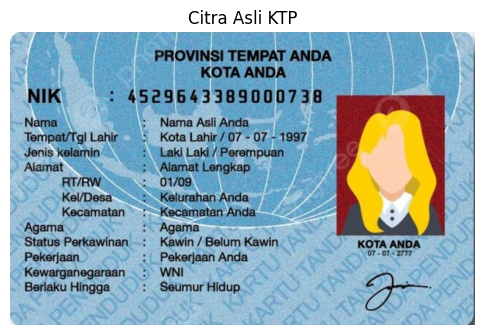

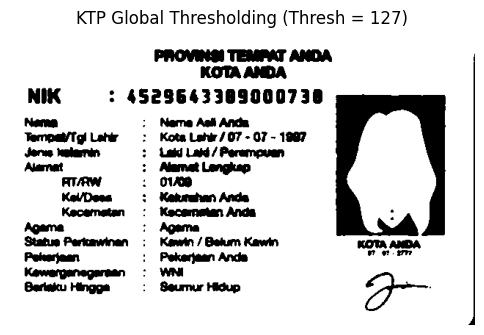

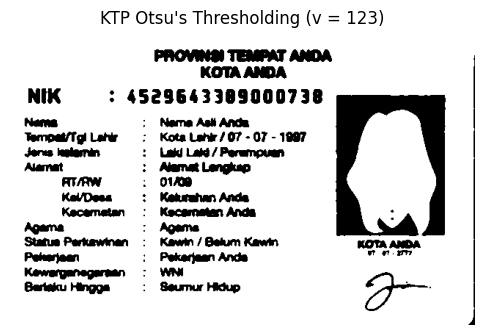

Seed [Dalam Koin] (45, 50) | intensitas: 175.000000


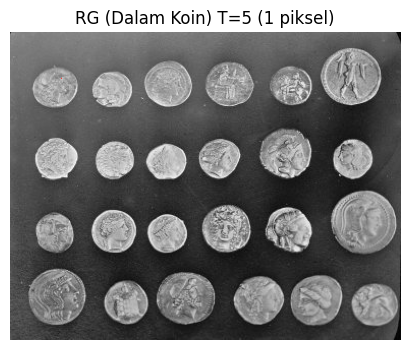

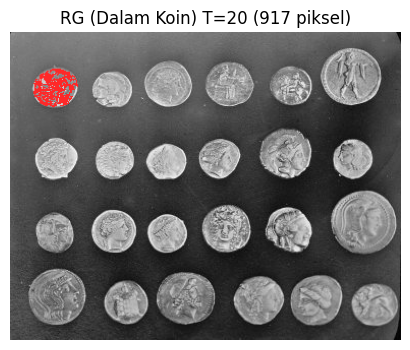

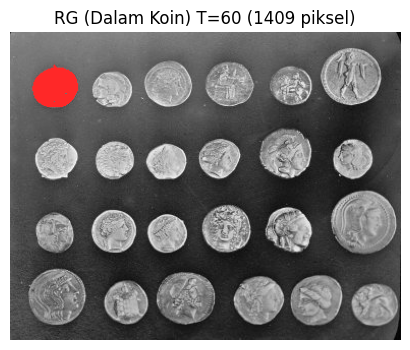

Seed [Latar Belakang] (10, 10) | intensitas: 127.000000


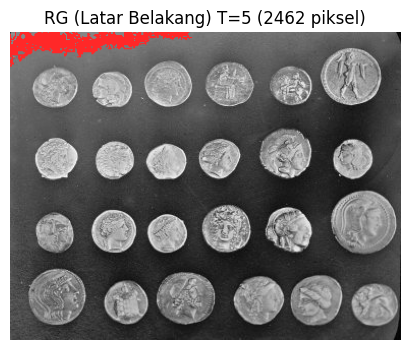

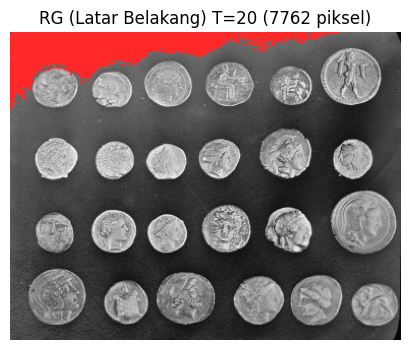

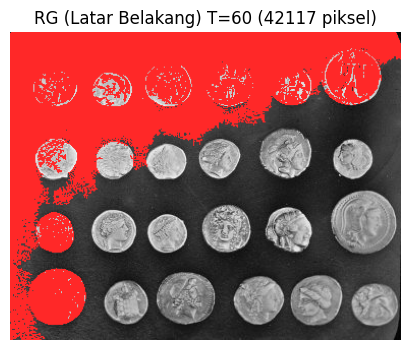

Seed [Tepi Koin] (36, 43) | intensitas: 159.000000


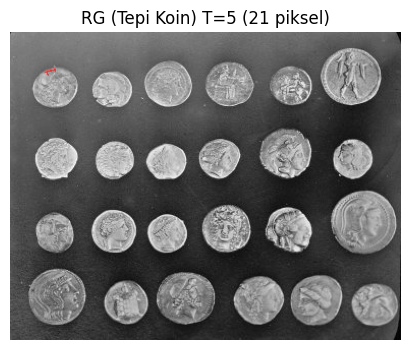

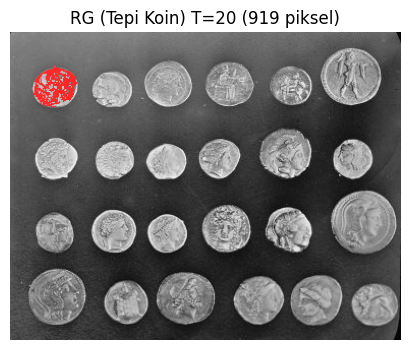

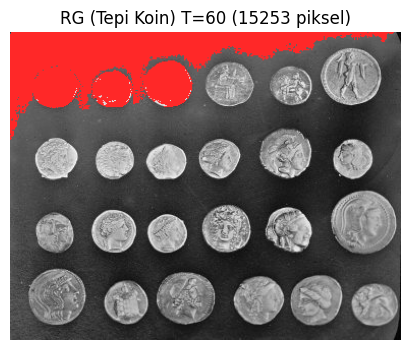

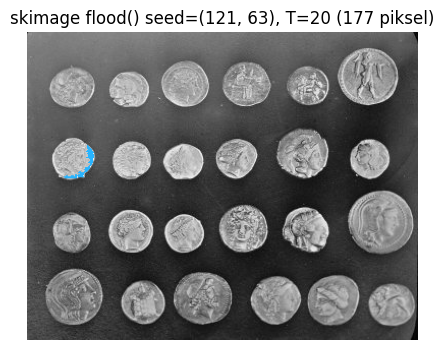

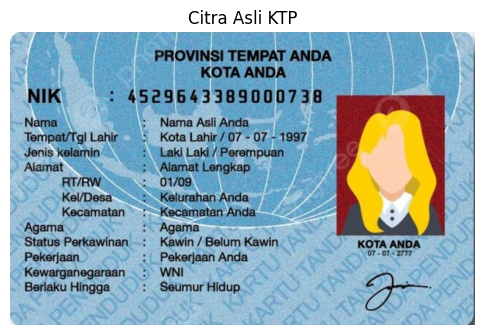

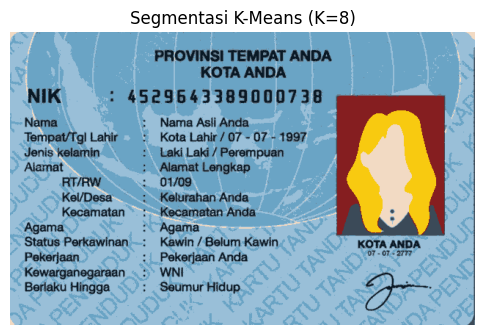

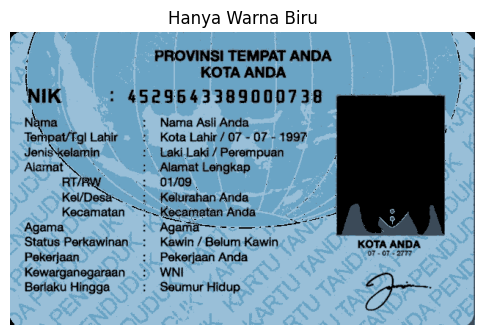

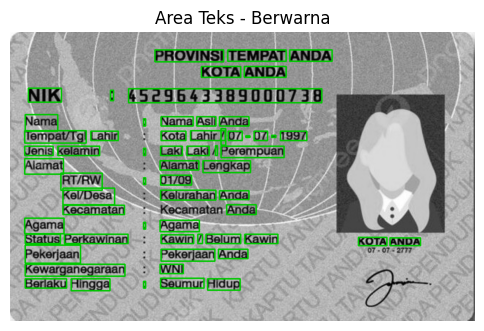

=== Hasil OCR [Berwarna] | Rata-rata Confidence: 80.78 ===
PROVINSI TEMPAT ANDA
KOTA ANDA

NIK : 4529643389000738
Nama : Nama Asli Anda
Tempat/Tg! Lahir ; Kota Lahir / 07 - 07 - 1997
Jenis kelamin 1 kaki Laki / Perempuan
Alamat 2. Alamat Lengkap

RT/RW : 01/09

Kel/Desa 1. Kelurahan Anda

Kecamatan — : Kecamatan Anda
Agama : Agama
Status Perkawinan —.: Kawin / Belum Kawin KOTA ANDA
Pekerjaan 1. Pekerjaan Anda una tea
Kewarganegaraan : WNI
Berlaku Hingga : Seumur Hidup Daan



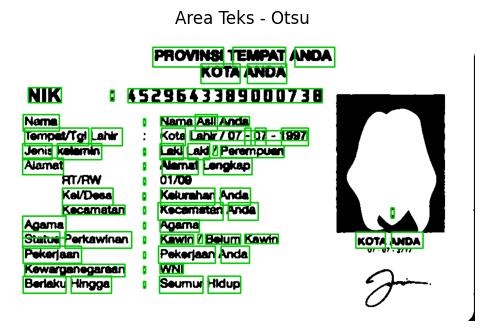

=== Hasil OCR [Otsu] | Rata-rata Confidence: 84.11 ===
PROVINSI TEMPAT ANDA
KOTA ANDA
NIK : 4529643389000738
Nama : Nama Asil Anda
Tempat/Tgi Lahir —: Kota Lahir/07 - 07 - 1997
Jenis kelamin 1 Laki Laki / Perampuan
Alamat : Alamat Lengkap
RTRW : 018
Kel/Desa 2 Kelurahan Anda
Kecamatan : Kecamatan Anda :
Agama : Agama
Status Perkawinan : Kawin / Belum Kawin KOTA ANDA
Pekerjaan 1 Pekerjaan Anda Om
Kewarganegaraan : WNI
Berlaku Hingga 1 Seumur Hidup oo



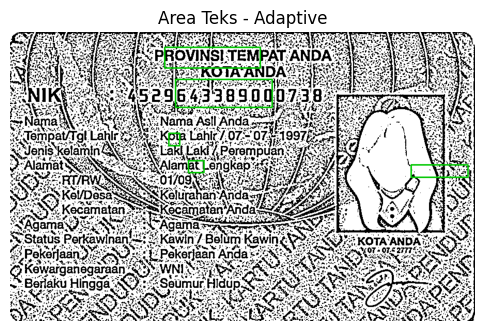

=== Hasil OCR [Adaptive] | Rata-rata Confidence: 27.22 ===
AI en eee ROVINSLTEM| DAEs oe bak
SEN Ba SISA adi SEK TAANDA ANA aca .
SN) Ta aa "OM KOTAANDA ne Bes oe .
Na oe 64398900 0738. pe ee Hang
IN Ten an 5049 Ha nu ewe “aa - 8
“NIK Tya Ba ge PME 7, VS
ae oy NN e
Sh ANN ae ota Lani 0705 ae KE q. Ve
ee ea ; - 4
ONE eed lamin? SOREN PA at Lengkaps Ns ERY Ss
(Jenis Kelar TN Naam eka uk .
Nania: Umat na Jb UN »
ee NG S
ya N Kel Desa Skesamat Na TE AYI S
oe ee Se MANA
Ma an anu EO OS
ea ee ake aan Aiea han Pala ea Di
Et EA
eS an
an Sak peter KO SEA KOKO Ha KA LA BIAN Nai
RP on by

Reh AL as ERD EN PSSST

EAE ANA

ese ON ee,

   No Teks sebenarnya OCR Berwarna     OCR Otsu OCR Adaptive
0   1        PROVINSI        Cocok        Cocok  Tidak cocok
1   2         JAKARTA  Tidak cocok  Tidak cocok  Tidak cocok
2   3             NIK        Cocok        Cocok        Cocok
3   4        SURABAYA  Tidak cocok  Tidak cocok  Tidak cocok
4   5           ISLAM  Tidak cocok  Tidak cocok  Tidak cocok
5   

In [7]:
from collections import deque
import glob
import math
import os
from google.colab import drive
from google.colab.patches import cv2_imshow
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
from skimage import color, data, feature, filters, morphology, segmentation
from skimage.filters import gaussian
from skimage.segmentation import flood
import pytesseract
from pytesseract import Output

# --- Bagian A: Mount Drive & Konfigurasi Path ---
drive.mount("/content/drive")
folder_path = "/content/drive/MyDrive/PCVK/Images"


def tampil_citra(im, judul, cmap=None, vmin=None, vmax=None):
  plt.figure(figsize=(6, 4))
  if cmap is not None:
    plt.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax)
  else:
    plt.imshow(im)
  plt.title(judul)
  plt.axis("off")
  plt.show()


# --- Bagian B: Global Threshold Manual (D1.3) ---
img_grad = cv.imread(folder_path + "/gradient.jpg", cv.IMREAD_GRAYSCALE)
thresh_g = 200
maxval_g = 255

th_binary = np.where(img_grad > thresh_g, maxval_g, 0).astype(np.uint8)
th_binary_inv = np.where(img_grad > thresh_g, 0, maxval_g).astype(np.uint8)
th_trunc = np.where(img_grad > thresh_g, thresh_g, img_grad).astype(np.uint8)
th_tozero = np.where(img_grad > thresh_g, img_grad, 0).astype(np.uint8)
th_tozero_inv = np.where(img_grad > thresh_g, 0, img_grad).astype(np.uint8)

for im, judul in [
    (img_grad, "Original Image"),
    (th_binary, "BINARY"),
    (th_binary_inv, "BINARY_INV"),
    (th_trunc, "TRUNC"),
    (th_tozero, "TOZERO"),
    (th_tozero_inv, "TOZERO_INV"),
]:
  tampil_citra(im, judul, cmap="gray", vmin=0, vmax=255)

# --- Bagian C: Adaptive Threshold Manual (D1.4) ---
img_sudoku = cv.imread(folder_path + "/sudoku-original.jpg", cv.IMREAD_GRAYSCALE)
img_sudoku_smooth = cv.medianBlur(img_sudoku, 5).astype(np.float64)

th_global_127 = np.where(img_sudoku_smooth > 127, 255, 0).astype(np.uint8)

win_size = 11
pad = win_size // 2
c_val = 2.0
sigma_val = 2.0

padded = np.pad(img_sudoku_smooth, pad_width=pad, mode="reflect")
h_s, w_s = img_sudoku_smooth.shape

mean_local = np.zeros((h_s, w_s), dtype=np.float64)
for y in range(h_s):
  for x in range(w_s):
    mean_local[y, x] = np.mean(padded[y : y + win_size, x : x + win_size])

th_adapt_mean = np.where(
    img_sudoku_smooth > (mean_local - c_val), 255, 0
).astype(np.uint8)

ax_1d = np.arange(-pad, pad + 1, dtype=np.float64)
g_1d = np.exp(-(ax_1d**2) / (2 * sigma_val**2))
g_kernel = np.outer(g_1d, g_1d)
g_kernel /= np.sum(g_kernel)

gauss_local = np.zeros((h_s, w_s), dtype=np.float64)
for y in range(h_s):
  for x in range(w_s):
    gauss_local[y, x] = np.sum(padded[y : y + win_size, x : x + win_size] * g_kernel)

th_adapt_gauss = np.where(
    img_sudoku_smooth > (gauss_local - c_val), 255, 0
).astype(np.uint8)

for im, judul in [
    (img_sudoku.astype(np.uint8), "Citra Asli Sudoku"),
    (th_global_127, "Global Thresholding (T = 127)"),
    (th_adapt_mean, "Adaptive Mean - Manual"),
    (th_adapt_gauss, "Adaptive Gaussian - Manual"),
]:
  tampil_citra(im, judul, cmap="gray", vmin=0, vmax=255)

# --- Bagian D: Otsu Threshold Manual Lena LC & KTP (D1.5) ---
def otsu_manual(gray):
  total_pixels = gray.size
  hist, _ = np.histogram(gray.ravel(), bins=256, range=(0, 256))
  intensity = np.arange(256, dtype=np.float64)

  best_thresh = 0
  max_between_var = -1.0

  for t in range(1, 255):
    w_b = np.sum(hist[:t]) / total_pixels
    w_f = np.sum(hist[t:]) / total_pixels
    if w_b == 0 or w_f == 0:
      continue
    mu_b = np.sum(intensity[:t] * hist[:t]) / np.sum(hist[:t])
    mu_f = np.sum(intensity[t:] * hist[t:]) / np.sum(hist[t:])
    between_var = w_b * w_f * ((mu_b - mu_f) ** 2)
    if between_var > max_between_var:
      max_between_var = between_var
      best_thresh = t

  otsu_bin = np.where(gray > best_thresh, 255, 0).astype(np.uint8)
  return otsu_bin, best_thresh

img_lena_lc = cv.imread(folder_path + "/lena_gs_lc2.jpg", cv.IMREAD_GRAYSCALE)
blur_lena_lc = cv.GaussianBlur(img_lena_lc, (5, 5), 0)
global_lena_127 = np.where(blur_lena_lc > 127, 255, 0).astype(np.uint8)
otsu_lena_img, otsu_lena_t = otsu_manual(blur_lena_lc)

for im, judul in [
    (blur_lena_lc, "Citra Asli (Lena LC)"),
    (global_lena_127, "Global Thresholding (Thresh = 127)"),
    (otsu_lena_img, f"Otsu's Thresholding (v = {otsu_lena_t})"),
]:
  tampil_citra(im, judul, cmap="gray", vmin=0, vmax=255)

ktp_candidates = sorted(
    glob.glob(os.path.join(folder_path, "*ktp*")), key=str.lower
)
if not ktp_candidates:
  raise FileNotFoundError(
      f"File KTP tidak ditemukan di {folder_path}. Isi folder: {os.listdir(folder_path)}"
  )

ktp_path = ktp_candidates[0]
print("Memakai file KTP:", ktp_path)
img_ktp_bgr = cv.imread(ktp_path)
img_ktp_gray = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2GRAY)
blur_ktp = cv.GaussianBlur(img_ktp_gray, (5, 5), 0)
global_ktp_127 = np.where(blur_ktp > 127, 255, 0).astype(np.uint8)
otsu_ktp_img, otsu_ktp_t = otsu_manual(blur_ktp)

for im, judul in [
    (cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2RGB), "Citra Asli KTP"),
    (global_ktp_127, "KTP Global Thresholding (Thresh = 127)"),
    (otsu_ktp_img, f"KTP Otsu's Thresholding (v = {otsu_ktp_t})"),
]:
  tampil_citra(im, judul, cmap="gray" if len(im.shape) == 2 else None)

# --- Bagian E: Region Growing & flood() pada data.coins() (D1.6) ---
coins_img = data.coins()

def region_growing_4n(gray_arr, seed_pt, tol):
  h_c, w_c = gray_arr.shape
  visited = np.zeros((h_c, w_c), dtype=bool)
  mask = np.zeros((h_c, w_c), dtype=bool)
  seed_val = float(gray_arr[seed_pt[0], seed_pt[1]])
  q = deque([seed_pt])
  visited[seed_pt[0], seed_pt[1]] = True

  while q:
    r, c = q.popleft()
    if abs(float(gray_arr[r, c]) - seed_val) <= tol:
      mask[r, c] = True
      for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < h_c and 0 <= nc < w_c and not visited[nr, nc]:
          visited[nr, nc] = True
          q.append((nr, nc))
  return mask

seeds_info = [
    ("Dalam Koin", (45, 50)),
    ("Latar Belakang", (10, 10)),
    ("Tepi Koin", (36, 43)),
]
tolerances = [5, 20, 60]

for s_label, s_pt in seeds_info:
  s_intens = float(coins_img[s_pt[0], s_pt[1]])
  print(f"Seed [{s_label}] {s_pt} | intensitas: {s_intens:.6f}")
  for t_val in tolerances:
    rg_mask = region_growing_4n(coins_img, s_pt, t_val)
    vis_rg = np.dstack([coins_img, coins_img, coins_img]).astype(np.uint8)
    vis_rg[rg_mask] = [255, 40, 40]
    tampil_citra(
        vis_rg,
        f"RG ({s_label}) T={t_val} ({np.sum(rg_mask)} piksel)",
    )

flood_seed = (121, 63)
flood_mask = flood(coins_img, seed_point=flood_seed, tolerance=20, connectivity=1)
vis_flood = np.dstack([coins_img, coins_img, coins_img]).astype(np.uint8)
vis_flood[flood_mask] = [40, 180, 255]
tampil_citra(
    vis_flood,
    f"skimage flood() seed={flood_seed}, T=20 ({np.sum(flood_mask)} piksel)",
)

# --- Bagian F: Segmentasi Warna Biru KTP dengan K-Means & HSV (D1.7) ---
img_ktp_rgb = cv.cvtColor(img_ktp_bgr, cv.COLOR_BGR2RGB)
pixels_float = img_ktp_rgb.reshape((-1, 3)).astype(np.float32)
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 20, 1.0)
_, labels_km, centers_km = cv.kmeans(
    pixels_float, 8, None, criteria, 10, cv.KMEANS_PP_CENTERS
)
centers_u8 = np.uint8(centers_km)
kmeans_ktp = centers_u8[labels_km.flatten()].reshape(img_ktp_rgb.shape)

hsv_ktp = cv.cvtColor(kmeans_ktp, cv.COLOR_RGB2HSV)
h_ch, s_ch, v_ch = hsv_ktp[:, :, 0], hsv_ktp[:, :, 1], hsv_ktp[:, :, 2]
blue_mask = (h_ch >= 85) & (h_ch <= 130) & (s_ch >= 25) & (v_ch >= 40)

only_blue_ktp = np.zeros_like(kmeans_ktp)
only_blue_ktp[blue_mask] = kmeans_ktp[blue_mask]

for im, judul in [
    (img_ktp_rgb, "Citra Asli KTP"),
    (kmeans_ktp, "Segmentasi K-Means (K=8)"),
    (only_blue_ktp, "Hanya Warna Biru"),
]:
  tampil_citra(im, judul)

# --- Bagian G: Perbandingan OCR pada KTP (D2) ---
ocr_cfg = "--psm 6"
ocr_lang = "ind+eng"

ktp_resized = cv.resize(img_ktp_rgb, (900, 560), interpolation=cv.INTER_CUBIC)
ktp_gray_r = cv.cvtColor(ktp_resized, cv.COLOR_RGB2GRAY)

_, ktp_otsu_r = cv.threshold(
    cv.GaussianBlur(ktp_gray_r, (5, 5), 0),
    0,
    255,
    cv.THRESH_BINARY + cv.THRESH_OTSU,
)
ktp_adapt_r = cv.adaptiveThreshold(
    ktp_gray_r,
    255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    15,
    4,
)

variants = [
    ("Berwarna", ktp_resized, cv.cvtColor(ktp_gray_r, cv.COLOR_GRAY2RGB)),
    ("Otsu", ktp_otsu_r, cv.cvtColor(ktp_otsu_r, cv.COLOR_GRAY2RGB)),
    ("Adaptive", ktp_adapt_r, cv.cvtColor(ktp_adapt_r, cv.COLOR_GRAY2RGB)),
]

ocr_texts = {}
conf_summary = {}

for v_name, v_img, v_vis_base in variants:
  txt_out = pytesseract.image_to_string(v_img, lang=ocr_lang, config=ocr_cfg)
  ocr_texts[v_name] = txt_out

  df_ocr = pytesseract.image_to_data(
      v_img, lang=ocr_lang, config=ocr_cfg, output_type=Output.DATAFRAME
  )
  df_valid = df_ocr[df_ocr["text"].notna()].copy()
  df_valid["text_clean"] = df_valid["text"].astype(str).str.strip()
  df_valid = df_valid[df_valid["text_clean"] != ""]
  df_valid["conf_num"] = pd.to_numeric(df_valid["conf"], errors="coerce")
  df_valid = df_valid[df_valid["conf_num"] >= 0]

  mean_conf = float(df_valid["conf_num"].mean()) if len(df_valid) > 0 else 0.0
  conf_summary[v_name] = mean_conf

  box_canvas = v_vis_base.copy()
  for _, row in df_valid[df_valid["conf_num"] > 60].iterrows():
    x1, y1 = int(row["left"]), int(row["top"])
    x2, y2 = x1 + int(row["width"]), y1 + int(row["height"])
    cv.rectangle(box_canvas, (x1, y1), (x2, y2), (0, 200, 0), 2)

  tampil_citra(box_canvas, f"Area Teks - {v_name}")
  print(f"=== Hasil OCR [{v_name}] | Rata-rata Confidence: {mean_conf:.2f} ===")
  print(txt_out)

ref_items = [
    "PROVINSI",
    "JAKARTA",
    "NIK",
    "SURABAYA",
    "ISLAM",
    "KAWIN",
    "KARYAWAN",
    "SWASTA",
    "WNI",
    "SEUMUR",
]

rows_eval = []
for idx, item in enumerate(ref_items, start=1):
  row_dict = {"No": idx, "Teks sebenarnya": item}
  for v_name in ["Berwarna", "Otsu", "Adaptive"]:
    found = item.lower() in ocr_texts[v_name].lower()
    row_dict[f"OCR {v_name}"] = "Cocok" if found else "Tidak cocok"
    row_dict[f"_match_{v_name}"] = int(found)
  rows_eval.append(row_dict)

df_table = pd.DataFrame(rows_eval)
print(df_table[["No", "Teks sebenarnya", "OCR Berwarna", "OCR Otsu", "OCR Adaptive"]])

summary_rows = []
for v_name in ["Berwarna", "Otsu", "Adaptive"]:
  matched_cnt = int(df_table[f"_match_{v_name}"].sum())
  pct = (matched_cnt / len(ref_items)) * 100.0
  summary_rows.append({
      "Citra masukan OCR": v_name,
      "Item terbaca tepat": f"{matched_cnt}/{len(ref_items)}",
      "Kecocokan (%)": f"{pct:.1f}%",
      "Rata-rata confidence": f"{conf_summary[v_name]:.2f}",
  })

print("\n=== Ringkasan Kecocokan OCR ===")
print(pd.DataFrame(summary_rows))